In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [5]:
df = pd.read_csv("student-scores.csv")

In [44]:
# Subject columns (all columns ending with '_score')
subject_cols = [c for c in df.columns if c.endswith("_score")]

# a) Bar graph: average marks of male and female students across all subjects
gender_subject_means = df.groupby("gender")[subject_cols].mean()
gender_subject_means

,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
gender,,,,,,,
female,82.792415,80.495010,80.678643,80.382236,79.216567,81.740519,80.953094
male,84.114228,80.168337,81.996994,79.606212,79.947896,80.812625,80.822645


<Axes: ylabel='Frequency'>

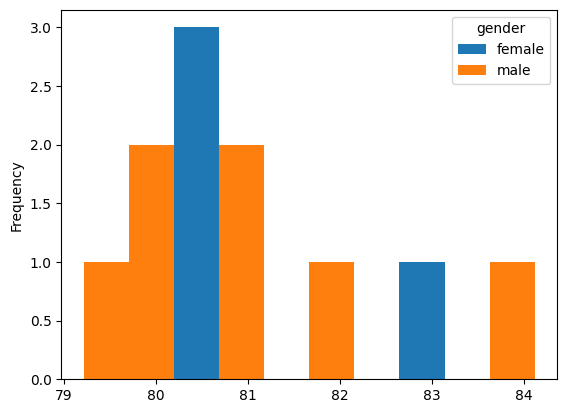

In [72]:
gender_subject_means.T.plot(kind="hist")

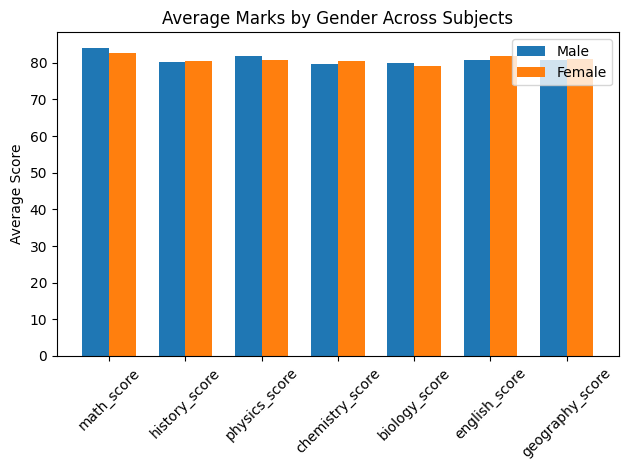

In [66]:



    # Create grouped bar chart (subjects on x-axis, bars for male/female)
    plt.figure()
    x = np.arange(len(subject_cols))
    width = 0.35

    plt.bar(x - width/2, gender_subject_means.loc["male"], width, label="Male")
    plt.bar(x + width/2, gender_subject_means.loc["female"], width, label="Female")
    plt.xticks(x, subject_cols, rotation=45)
    plt.ylabel("Average Score")
    plt.title("Average Marks by Gender Across Subjects")
    plt.legend()
    plt.tight_layout()
    plt.show()



In [68]:
# b) Line graph: avg marks of all subjects for students with and without part-time jobs
job_means = df.groupby("part_time_job")[subject_cols].mean()
job_means

,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
part_time_job,,,,,,,
False,84.514846,80.942993,82.009501,80.488717,79.605701,81.792162,81.040974
True,77.787975,77.075949,77.750000,77.363924,79.452532,78.534810,80.072785


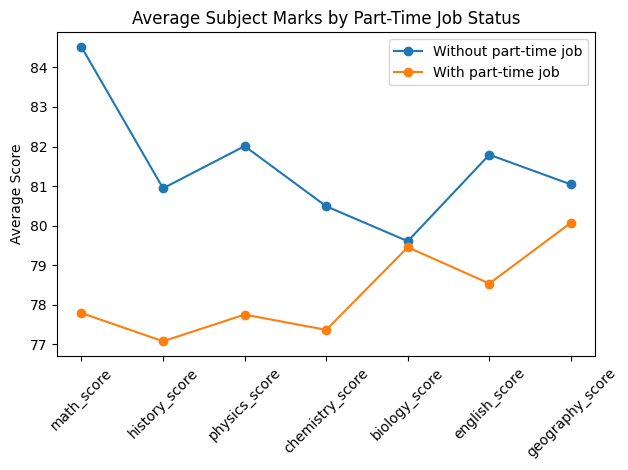

In [7]:

 

    plt.figure()
    for has_job, row in job_means.iterrows():
        label = "With part-time job" if has_job else "Without part-time job"
        plt.plot(subject_cols, row.values, marker="o", label=label)

    plt.xticks(rotation=45)
    plt.ylabel("Average Score")
    plt.title("Average Subject Marks by Part-Time Job Status")
    plt.legend()
    plt.tight_layout()
    plt.show()


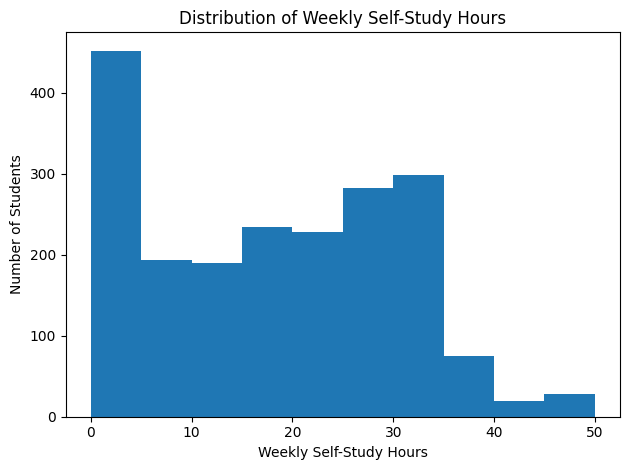

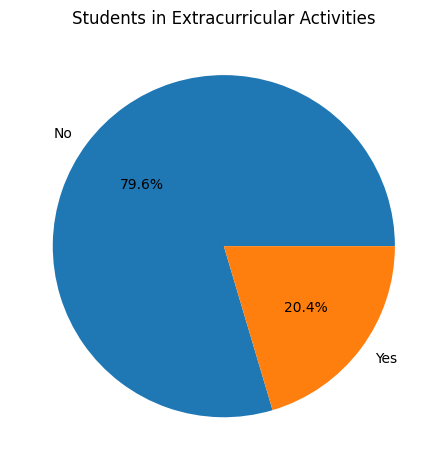

In [8]:

    # c) Histogram: distribution of weekly self-study hours
    plt.figure()
    plt.hist(df["weekly_self_study_hours"], bins=10)
    plt.xlabel("Weekly Self-Study Hours")
    plt.ylabel("Number of Students")
    plt.title("Distribution of Weekly Self-Study Hours")
    plt.tight_layout()
    plt.show()

    # d) Pie chart: percentage of students engaged in extracurricular activities
    counts = df["extracurricular_activities"].value_counts()
    labels = ["No", "Yes"]
    sizes = [counts.get(False, 0), counts.get(True, 0)]

    plt.figure()
    plt.pie(sizes, labels=labels, autopct="%1.1f%%")
    plt.title("Students in Extracurricular Activities")
    plt.tight_layout()
    plt.show()